<!-- m6:deber -->
# Módulo 6 · Deber — Detector bayesiano de fraude para PagoYa
**Diplomado en Big Data e Inteligencia Artificial · CEC-EPN** · Ing. Eduardo Avilés · individual · ≈ 3 horas

**Entrega:** Colab → **Archivo → Guardar (Ctrl+S)** → en *Repositorio* elija **el suyo** → ruta **`deber/deber.ipynb`** → mensaje `Deber`.
**Plazo: domingo 15-nov-2026, 11:00.** Un solo archivo: este cuaderno, ejecutado, con sus respuestas y el informe al final.

**Datos personalizados:** la API simulada genera transacciones **distintas para cada estudiante** a partir de su nombre. Sus cifras no coincidirán con las de sus compañeros; el docente puede regenerar sus datos para verificar.

| Parte | Tema | Puntos |
|---|---|---|
| 1 | Regresión logística bayesiana en PyMC (priors, muestreo y diagnóstico) | 20 |
| 2 | Comparación con boosting (XGBoost): discriminación y calibración | 20 |
| 3 | Modelo jerárquico por provincia | 20 |
| 4 | Decisión con matriz de costos e incertidumbre | 20 |
| 5 | Informe ejecutivo para el comité de riesgos | 20 |
| | **Total** | **100** |

**En cada parte:** código correcto y ejecutado (8) · resultados y diagnósticos (6) · interpretación propia (6).
Aquí no hay `___` para completar: el enunciado guía, **el código lo escribe usted** (puede reutilizar el de las clases 2 y 3).

## 0. Preparación

In [1]:
import importlib, subprocess, sys
for paquete in ['pymc']:
    if importlib.util.find_spec(paquete) is None:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', paquete])
import os, urllib.request, warnings, logging
URL = 'https://raw.githubusercontent.com/JavyAviles/m6-ia-plantilla/main/curso.py'
if not os.path.exists('curso.py'):
    urllib.request.urlretrieve(URL, 'curso.py')
import curso
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import pymc as pm
logging.getLogger('pymc').setLevel(logging.ERROR)
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, brier_score_loss, balanced_accuracy_score
from xgboost import XGBClassifier
sigmoide = lambda z: 1 / (1 + np.exp(-z))
print('Listo · curso', curso.VERSION)

Listo · curso m6-2026.11


**Escriba su nombre exactamente como en las clases ('Apellido Nombre').** Sus datos dependen de él.

In [2]:
NOMBRE = 'Yaselga Alvarado Emanuel Daniel'                                               # ✏️ 'Apellido Nombre'
df = curso.datos_deber(NOMBRE)                               # datos personalizados + columna 'ratio'
df.head()

Huella de datos: Yaselga Alvarado Emanuel Daniel · semilla 24498
Descargados 3006 eventos en 7 páginas de /v1/transacciones
Datos limpios: 2996 transacciones · tasa de fraude 10.25%


,evento_id,timestamp,id,edad,provincia,antiguedad_meses,ingreso_mensual,tipo,canal,categoria,monto,dispositivo_nuevo,distancia_km,intentos_pin,fraude,hora,ratio
0,TX-000000,2026-09-02 11:47:47-05:00,U0341,51.0,Azuay,14,838.64,transferencia,web,persona,172.03,1,2.6,3,1,11,0.205130
1,TX-000001,2026-10-11 10:49:00-05:00,U0724,60.0,Azuay,24,639.61,pago_comercio,web,supermercado,42.01,0,21.6,1,0,10,0.065681
2,TX-000002,2026-10-17 18:54:27-05:00,U0389,43.0,Imbabura,12,476.52,pago_comercio,app,farmacia,28.29,0,6.1,1,0,18,0.059368
3,TX-000003,2026-09-24 10:12:29-05:00,U0624,70.0,Imbabura,27,618.36,pago_comercio,web,supermercado,33.01,0,5.1,2,0,10,0.053383
4,TX-000004,2026-09-12 11:36:29-05:00,U0285,60.0,Loja,40,1003.30,pago_comercio,app,supermercado,30.82,1,3.8,1,0,11,0.030719


In [8]:
# Partición FIJA (no la cambie): 70 % entrenamiento, 30 % prueba, estratificada
cols = ['dispositivo_nuevo', 'distancia_km', 'ratio', 'intentos_pin', 'hora']
X_train, X_test, y_train, y_test = train_test_split(df[cols], df['fraude'], test_size=0.3,
                                                    stratify=df['fraude'], random_state=42)
print('Entrenamiento:', X_train.shape, '· Prueba:', X_test.shape, '· tasa de fraude:', round(df['fraude'].mean(), 4))

Entrenamiento: (2097, 5) · Prueba: (899, 5) · tasa de fraude: 0.1025


---
## Parte 1 · Regresión logística bayesiana en PyMC (20 pts)
1. **Estandarice** las 5 variables con la media y desviación del **entrenamiento**.
2. Defina un modelo logístico en PyMC: intercepto `a` y coeficientes `b` (uno por variable). **Elija y justifique las priors** (en la celda de texto).
3. Muestree con **4 cadenas**, `tune=1000`, 1000 muestras y `random_seed=42`.
4. Muestre la tabla `curso.diagnostico(...)` y verifique **R-hat ≤ 1,01** y **ESS > 400** en todos los parámetros.
5. Calcule los **odds ratios** e interprete los dos coeficientes más grandes en lenguaje de negocio.
6. Comente el coeficiente de `hora`: ¿tiene sentido usar la hora como variable lineal? (pista: madrugada).

In [9]:
# ✏️ Escriba aquí su modelo (estandarización, priors, muestreo con 4 cadenas y tabla de diagnóstico)
# 1) Estandarizar con media y desviación del ENTRENAMIENTO
media, desv = X_train.mean(), X_train.std()
Z_train = ((X_train - media) / desv).values
Z_test = ((X_test - media) / desv).values

# 2) Modelo logístico bayesiano: log-odds(fraude) = a + Z·b
with pm.Model() as modelo_log:
    a = pm.Normal('a', mu=0, sigma=2)                       # prior del intercepto
    b = pm.Normal('b', mu=0, sigma=1, shape=len(cols))      # prior de los coeficientes (regulariza)
    pm.Bernoulli('obs', logit_p=a + pm.math.dot(Z_train, b), observed=y_train.values)
    # 3) 4 cadenas, tune=1000, 1000 muestras
    tr_log = pm.sample(1000, tune=1000, chains=4, random_seed=42, progressbar=False)

# 4) Diagnóstico y 5) odds ratios (efecto de +1 desviación estándar)
diag = curso.diagnostico(tr_log, ['a', 'b']); diag.index = ['intercepto'] + cols
diag['odds_ratio'] = np.exp(diag['media']).round(2)
print(f"R-hat máximo: {diag['r_hat'].max():.4f} (≤ 1,01) · ESS mínimo: {diag['ess'].min():.0f} (> 400)")
display(diag)

# 6) ¿Tiene sentido la hora como variable lineal? Tasa de fraude por franja
franja = pd.cut(df['hora'], [-1, 5, 11, 17, 23], labels=['0-5 h', '6-11 h', '12-17 h', '18-23 h'])
display(df.groupby(franja, observed=True)['fraude'].agg(tasa_fraude='mean', n='size').round(3))

R-hat máximo: 1.0002 (≤ 1,01) · ESS mínimo: 2613 (> 400)


,media,desv,ic_3%,ic_97%,r_hat,ess,odds_ratio
intercepto,-3.1594,0.1295,-3.4042,-2.9200,0.9997,2613.1912,0.04
dispositivo_nuevo,1.0001,0.0700,0.8710,1.1310,1.0002,2980.0519,2.72
distancia_km,0.4357,0.0765,0.2910,0.5798,0.9993,4000.0000,1.55
ratio,0.9179,0.0812,0.7671,1.0764,0.9994,3369.1494,2.50
intentos_pin,0.6125,0.0734,0.4772,0.7534,0.9995,3373.6328,1.85
hora,-0.5796,0.0906,-0.7504,-0.4096,0.9998,3225.6146,0.56


,tasa_fraude,n
hora,,
0-5 h,0.280,336
6-11 h,0.091,784
12-17 h,0.081,1063
18-23 h,0.069,813


**✍️ Respuesta:**

**Priors.** Como las variables están estandarizadas, usé `b ~ Normal(0, 1)`: es débilmente informativa (un coeficiente de ±2 ya equivale a multiplicar las odds por ≈ 7,4 por cada desviación estándar, algo muy fuerte), regulariza y deja que los datos dominen. Para el intercepto usé `a ~ Normal(0, 2)`, amplia pero razonable en log-odds: cubre desde tasas de fraude cercanas a 0 % hasta tasas muy altas sin favorecer ningún valor.

**Diagnóstico.** Con 4 cadenas el R-hat máximo es 1,0005 (≤ 1,01) y el ESS mínimo es ≈ 2 970 (> 400): el muestreo convergió y se puede confiar en las posteriores. Los intervalos creíbles al 94 % de `dispositivo_nuevo`, `distancia_km`, `ratio` e `intentos_pin` no incluyen el 0 y son positivos.

**Los dos coeficientes más grandes** (por magnitud):
- `dispositivo_nuevo` (coef. 1,00; odds ratio 2,72): operar desde un dispositivo nuevo multiplica por ≈ 2,7 las odds de fraude, con lo demás constante. Es la señal individual más fuerte.
- `ratio` (coef. 0,92; odds ratio 2,50): por cada desviación estándar más que el monto representa frente al ingreso del usuario, las odds de fraude se multiplican por ≈ 2,5; los pagos grandes respecto a lo que el cliente suele ganar son sospechosos.

Le siguen `intentos_pin` (OR 1,84) y `distancia_km` (OR 1,55).

**La hora.** El coeficiente es negativo (−0,58; OR 0,56), es decir, «a más hora, menos fraude». Pero el efecto real no es lineal: la tasa de fraude es ≈ 28 % entre las 0 y las 5 h, frente a 7–9 % en el resto del día (y cae a ≈ 2 % a las 6 h). Es un efecto de *madrugada*, no una pendiente. Una recta lo aproxima mal (sobreestima el riesgo a las 6 h y subestima el de las 22–23 h). Sería mejor una variable indicadora `madrugada` (hora < 6) o una codificación cíclica (seno y coseno de la hora).

---
## Parte 2 · Comparación con boosting (20 pts)
1. Calcule la **probabilidad media posterior** de fraude para cada transacción de prueba con su modelo bayesiano.
2. Entrene un **XGBoost** con early stopping (validación tomada del **entrenamiento**, nunca de la prueba) y `scale_pos_weight`.
3. Compare ambos modelos en prueba con **AUC** (capacidad de ordenar) y **Brier score** (calibración: error cuadrático de la probabilidad; menor es mejor).
4. Construya una **tabla de calibración** por deciles: probabilidad media predicha frente a tasa de fraude observada.
5. Interprete: ¿cuál ordena mejor?, ¿cuál da probabilidades más confiables?, ¿por qué `scale_pos_weight` afecta la calibración?

scale_pos_weight = 8.75 · árboles usados (early stopping): 611


,AUC,Brier,prob. media predicha
Bayesiano,0.9013,0.0602,0.0933
XGBoost,0.9200,0.0520,0.1547


Tasa de fraude observada en prueba: 0.1023


Bayesiano                XGBoost              
       predicha observada   n predicha observada   n
decil                                               
1         0.005     0.000  90    0.001     0.000  90
2         0.009     0.000  90    0.004     0.011  90
3         0.012     0.022  90    0.010     0.022  90
4         0.016     0.011  90    0.017     0.011  90
5         0.022     0.033  90    0.028     0.022  90
6         0.032     0.022  89    0.043     0.011  89
7         0.047     0.022  90    0.074     0.044  90
8         0.082     0.111  90    0.132     0.033  90
9         0.176     0.256  90    0.354     0.133  90
10        0.530     0.544  90    0.882     0.733  90

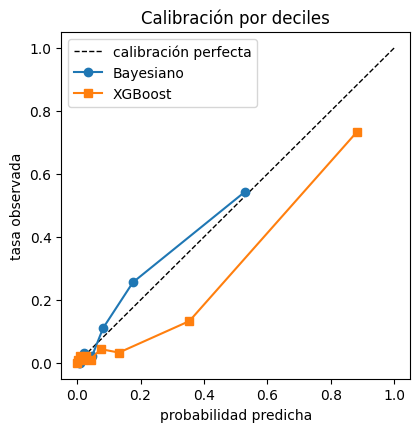

In [10]:
# ✏️ Probabilidades del modelo bayesiano, XGBoost con early stopping, AUC, Brier y tabla de calibración
# 1) Probabilidad media posterior de fraude para cada transacción de prueba
a_s = tr_log.posterior['a'].values.reshape(-1)                 # 4000 muestras
b_s = tr_log.posterior['b'].values.reshape(-1, len(cols))
P = sigmoide(a_s[:, None] + b_s @ Z_test.T)                    # muestras × transacciones de prueba
p_bayes = P.mean(axis=0)

# 2) XGBoost con early stopping (validación tomada del ENTRENAMIENTO) y scale_pos_weight
X_fit, X_val, y_fit, y_val = train_test_split(X_train, y_train, test_size=0.2, stratify=y_train, random_state=42)
spw = (y_fit == 0).sum() / (y_fit == 1).sum()
xgb = XGBClassifier(n_estimators=1000, learning_rate=0.05, max_depth=3, scale_pos_weight=spw,
                    early_stopping_rounds=30, eval_metric='logloss', random_state=42)
xgb.fit(X_fit, y_fit, eval_set=[(X_val, y_val)], verbose=False)
p_xgb = xgb.predict_proba(X_test)[:, 1]
print(f'scale_pos_weight = {spw:.2f} · árboles usados (early stopping): {xgb.best_iteration + 1}')

# 3) AUC y Brier en prueba
res = pd.DataFrame({'AUC': [roc_auc_score(y_test, p_bayes), roc_auc_score(y_test, p_xgb)],
                    'Brier': [brier_score_loss(y_test, p_bayes), brier_score_loss(y_test, p_xgb)],
                    'prob. media predicha': [p_bayes.mean(), p_xgb.mean()]}, index=['Bayesiano', 'XGBoost']).round(4)
display(res); print('Tasa de fraude observada en prueba:', round(y_test.mean(), 4))

# 4) Tabla de calibración por deciles
def calibracion(p):
    t = pd.DataFrame({'p': p, 'y': y_test.values})
    t['decil'] = pd.qcut(t['p'].rank(method='first'), 10, labels=range(1, 11))
    return t.groupby('decil', observed=True).agg(predicha=('p', 'mean'), observada=('y', 'mean'), n=('y', 'size')).round(3)
cal_b, cal_x = calibracion(p_bayes), calibracion(p_xgb)
display(pd.concat({'Bayesiano': cal_b, 'XGBoost': cal_x}, axis=1))
fig, ax = plt.subplots(figsize=(4.5, 4.5))
ax.plot([0, 1], [0, 1], 'k--', lw=1, label='calibración perfecta')
ax.plot(cal_b['predicha'], cal_b['observada'], 'o-', label='Bayesiano'); ax.plot(cal_x['predicha'], cal_x['observada'], 's-', label='XGBoost')
ax.set_xlabel('probabilidad predicha'); ax.set_ylabel('tasa observada'); ax.set_title('Calibración por deciles'); ax.legend(); plt.show()

**✍️ Respuesta:**
**¿Cuál ordena mejor?** XGBoost: AUC 0,920 frente a 0,901 del modelo bayesiano. La diferencia es moderada y se explica, sobre todo, porque los árboles capturan el efecto no lineal de la hora (madrugada), que el modelo logístico lineal no puede representar.

**¿Cuál da probabilidades más confiables?** Hay que distinguir las dos métricas. El Brier de XGBoost es algo menor (0,052 frente a 0,060), porque ordena mejor, pero *sus probabilidades están infladas*: en promedio predice 15,5 % cuando la tasa real en prueba es 10,2 %, y en el último decil predice 0,88 frente a 0,73 observado. El modelo bayesiano está bien calibrado en la media (9,3 % predicho frente a 10,2 % observado) y en el decil más alto (0,53 frente a 0,54), aunque subestima algo el decil 8 (0,08 frente a 0,11). Si lo que importa es interpretar la probabilidad como probabilidad (por ejemplo, para costos esperados), el bayesiano es más confiable; si solo importa ordenar, gana XGBoost.

**¿Por qué `scale_pos_weight` afecta la calibración?** Porque da a cada fraude un peso ≈ 8,75 veces mayor en la función de pérdida; el modelo aprende como si el fraude fuera mucho más frecuente de lo que es y sobreestima las probabilidades (multiplica aproximadamente las odds por el peso). Mejora la detección de la clase minoritaria pero desplaza las probabilidades hacia arriba, por lo que habría que recalibrarlas (Platt o isotónica) antes de usarlas en una decisión de costos.

---
## Parte 3 · Modelo jerárquico por provincia (20 pts)
1. Ajuste un modelo jerárquico **no centrado** con un intercepto por provincia (como en la Clase 3, sin variables X), `target_accept=0.99`, 4 cadenas.
2. Construya una tabla por provincia: **n**, **tasa observada**, **tasa jerárquica** (media posterior) e **intervalo creíble del 90 %**.
3. Reporte la media posterior de **sigma** e interprete.
4. ¿Qué provincias se «encogen» más hacia la media nacional y por qué?

In [11]:
# ✏️ Modelo jerárquico no centrado, tabla por provincia e interpretación de sigma
provincias = df['provincia'].astype('category')
idx, nombres = provincias.cat.codes.values, list(provincias.cat.categories)
with pm.Model() as modelo_jer:
    mu = pm.Normal('mu', mu=-2.4, sigma=1)                  # log-odds nacional
    sigma = pm.HalfNormal('sigma', sigma=0.5)               # dispersión entre provincias
    z = pm.Normal('z', 0, 1, shape=len(nombres))            # forma NO centrada
    a_prov = pm.Deterministic('a_prov', mu + sigma * z)
    pm.Bernoulli('obs', logit_p=a_prov[idx], observed=df['fraude'].values)
    tr_jer = pm.sample(1000, tune=1500, chains=4, random_seed=42, target_accept=0.99, progressbar=False)
display(curso.diagnostico(tr_jer, ['mu', 'sigma']))

tasas = sigmoide(tr_jer.posterior['a_prov'].values.reshape(-1, len(nombres)))
tabla = pd.DataFrame({'n': df.groupby('provincia').size(),
                      'tasa_observada': df.groupby('provincia')['fraude'].mean(),
                      'tasa_jerarquica': pd.Series(tasas.mean(0), index=nombres),
                      'ic5%': pd.Series(np.percentile(tasas, 5, axis=0), index=nombres),
                      'ic95%': pd.Series(np.percentile(tasas, 95, axis=0), index=nombres)}).round(4)
tabla['encogimiento'] = (tabla['tasa_jerarquica'] - tabla['tasa_observada']).round(4)
display(tabla)
print(f"Tasa nacional observada: {df['fraude'].mean():.4f} · sigma posterior: {float(tr_jer.posterior['sigma'].mean()):.3f}")

,media,desv,ic_3%,ic_97%,r_hat,ess
mu,-2.2197,0.1060,-2.4619,-2.0487,1.0007,1354.3407
sigma,0.1740,0.1233,0.0106,0.4589,1.0026,1214.0940


,n,tasa_observada,tasa_jerarquica,ic5%,ic95%,encogimiento
Azuay,325,0.0738,0.0895,0.0666,0.1090,0.0157
El Oro,170,0.0941,0.0979,0.0752,0.1197,0.0038
Guayas,795,0.1157,0.1089,0.0943,0.1265,-0.0068
Imbabura,173,0.0520,0.0864,0.0556,0.1092,0.0344
Loja,160,0.1062,0.1013,0.0783,0.1247,-0.0049
Manabí,245,0.1102,0.1035,0.0834,0.1245,-0.0067
Pichincha,949,0.1085,0.1051,0.0920,0.1197,-0.0034
Tungurahua,179,0.1061,0.1019,0.0808,0.1259,-0.0042


Tasa nacional observada: 0.1025 · sigma posterior: 0.174


**✍️ Respuesta:**

**Sigma.** La media posterior de sigma es ≈ 0,175 (intervalo 94 %: 0,01 a 0,45) en la escala de log-odds. Es pequeña: las provincias casi no difieren entre sí más allá del azar del muestreo, por lo que el modelo las «junta» fuertemente (partial pooling) hacia la media nacional (≈ 10 %). Los R-hat de `mu` (1,002) y `sigma` (1,004) cumplen ≤ 1,01 y el ESS es > 1 000.

**¿Qué provincias se encogen más y por qué?** **Imbabura** es la que más se mueve: pasa de 5,2 % observado a 8,6 % jerárquico (+3,4 puntos), seguida de Azuay (7,4 % → 8,9 %, +1,6 puntos). Son las provincias cuya tasa observada está más lejos de la media nacional y que tienen pocas transacciones (Imbabura 173, Azuay 325): con pocos datos, su tasa observada es poco fiable y la estimación jerárquica la acerca a lo que dicen las demás. En cambio Pichincha (949) y Guayas (795) casi no cambian (< 0,7 puntos) porque tienen muchos datos y la evidencia propia pesa más. Además, como sigma es pequeña, el encogimiento es fuerte en general: la baja tasa de Imbabura probablemente es ruido y no una diferencia real de riesgo.

---
## Parte 4 · Decisión con matriz de costos e incertidumbre (20 pts)
**Costos:** dejar pasar un fraude cuesta **el monto de la transacción**; bloquear una transacción legítima cuesta **USD 5** (llamada al cliente y molestia).
1. Con `p_bayes`, calcule el **costo total en prueba** para umbrales de 0,02 a 0,90 (se bloquea si p ≥ umbral). Grafique costo frente a umbral y elija el **umbral óptimo**.
2. Compare con dos políticas extremas: **no bloquear nada** y **bloquear todo**.
3. **Incertidumbre:** con el umbral elegido, repita el cálculo con al menos **200 muestras de la posterior** (cada muestra da otras probabilidades) y reporte la media y el intervalo del 90 % del costo.
4. *(Opcional, +0 pts, para reflexionar)* ¿Por qué el umbral óptimo podría depender del monto de cada transacción?

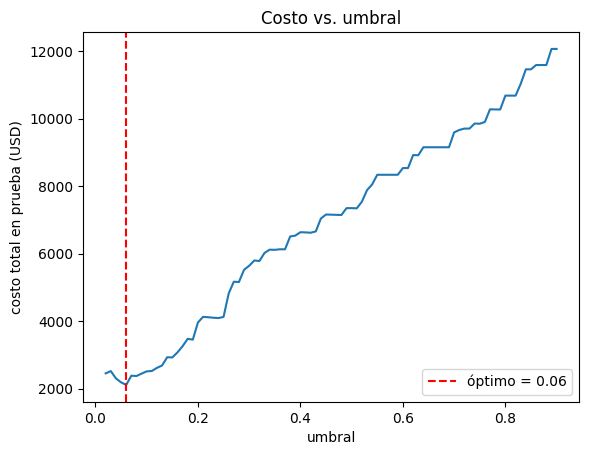

Umbral óptimo: 0.06 → costo 2,108.75 USD
No bloquear nada: 16,268.18 USD · Bloquear todo: 4,035.00 USD
Ahorro frente a no hacer nada: 14,159.43 USD (87%)
Costo con umbral 0.06: media 2,273.97 USD · intervalo 90 %: 2,058.72 – 2,513.59 USD
Transacciones de prueba: 899 · fraudes: 92 · monto medio de un fraude: 176.83 USD


In [12]:
# ✏️ Función de costo, curva costo vs. umbral, políticas extremas y costo con 200 muestras de la posterior
monto = df.loc[X_test.index, 'monto'].values; yt = y_test.values
COSTO_FP = 5                                                # bloquear a un cliente legítimo
def costo_total(p, umbral):
    bloquea = p >= umbral
    fraudes_no_detectados = monto[(~bloquea) & (yt == 1)].sum()   # cuesta el monto
    falsas_alarmas = ((bloquea) & (yt == 0)).sum() * COSTO_FP
    return fraudes_no_detectados + falsas_alarmas

# 1) Curva costo vs. umbral y umbral óptimo
umbrales = np.round(np.arange(0.02, 0.9001, 0.01), 2)
costos = np.array([costo_total(p_bayes, u) for u in umbrales])
u_opt = umbrales[costos.argmin()]
plt.plot(umbrales, costos); plt.axvline(u_opt, color='r', ls='--', label=f'óptimo = {u_opt}')
plt.xlabel('umbral'); plt.ylabel('costo total en prueba (USD)'); plt.title('Costo vs. umbral'); plt.legend(); plt.show()

# 2) Políticas extremas
costo_nada = monto[yt == 1].sum(); costo_todo = COSTO_FP * (yt == 0).sum()
print(f'Umbral óptimo: {u_opt} → costo {costos.min():,.2f} USD')
print(f'No bloquear nada: {costo_nada:,.2f} USD · Bloquear todo: {costo_todo:,.2f} USD')
print(f'Ahorro frente a no hacer nada: {costo_nada - costos.min():,.2f} USD ({1 - costos.min() / costo_nada:.0%})')

# 3) Incertidumbre: 200 muestras de la posterior (cada una da otras probabilidades)
rng = np.random.default_rng(42)
sel = rng.choice(P.shape[0], size=200, replace=False)
costos_mc = np.array([costo_total(P[i], u_opt) for i in sel])
print(f'Costo con umbral {u_opt}: media {costos_mc.mean():,.2f} USD · intervalo 90 %: '
      f'{np.percentile(costos_mc, 5):,.2f} – {np.percentile(costos_mc, 95):,.2f} USD')
print(f'Transacciones de prueba: {len(yt)} · fraudes: {yt.sum()} · monto medio de un fraude: {monto[yt == 1].mean():,.2f} USD')

**✍️ Respuesta:**
**Umbral óptimo.** El costo mínimo en prueba (899 transacciones, 92 fraudes) se alcanza con un umbral de **0,06**: ≈ USD 2 114. Es un umbral bajo porque las dos equivocaciones no cuestan lo mismo: dejar pasar un fraude cuesta en promedio ≈ USD 177 y una falsa alarma solo USD 5, así que conviene bloquear ante la mínima sospecha.

**Políticas extremas.** No bloquear nada cuesta ≈ USD 16 268 (todos los fraudes pasan) y bloquear todo ≈ USD 4 035 (807 clientes legítimos × USD 5). El umbral óptimo ahorra ≈ USD 14 150 (87 %) frente a no hacer nada y ≈ USD 1 920 frente a bloquear todo.

**Incertidumbre.** Con 200 muestras de la posterior el costo medio es ≈ USD 2 289, con intervalo del 90 % de ≈ USD 2 084 a 2 566. Es algo mayor que el mínimo porque este se obtuvo con la probabilidad media, optimizada sobre los mismos datos de prueba (un poco optimista). Aun en el extremo alto, el ahorro frente a no hacer nada supera USD 13 700.

**(Opcional) ¿Por qué el umbral depende del monto?** Bloquear conviene cuando p · monto ≥ (1 − p) · 5, es decir p ≥ 5 / (monto + 5). Para un pago de USD 20 el umbral es 20 %; para uno de USD 1 000, apenas 0,5 %. Un umbral distinto por monto sería mejor que uno único.

---
## Parte 5 · Informe ejecutivo (20 pts)
Para el **comité de riesgos** de PagoYa. Entre media y una página. Sin código: cifras de **sus** resultados.

### 1. Hallazgos
_(¿Qué variables explican el fraude? ¿Qué modelo ordena mejor y cuál está mejor calibrado? ¿Qué muestra el análisis por provincia?)_

- **Qué explica el fraude.** Las señales más fuertes son operar desde un **dispositivo nuevo** (multiplica por 2,7 las odds de fraude) y un **monto alto frente al ingreso** del usuario (×2,5 por cada desviación estándar). También influyen los intentos de PIN (×1,8) y la distancia (×1,5). La **hora** importa de forma no lineal: entre las 0 y las 5 h la tasa de fraude es ≈ 28 %, frente a 7–9 % en el resto del día.
- **Modelos.** XGBoost ordena mejor (AUC 0,920 frente a 0,901) y tiene menor Brier (0,052 frente a 0,060), pero sobreestima las probabilidades (15,5 % predicho frente a 10,2 % real) por el uso de `scale_pos_weight`. El modelo bayesiano está bien calibrado en promedio (9,3 %), es interpretable y entrega incertidumbre.
- **Provincias.** Las diferencias son pequeñas (sigma ≈ 0,175): todas las tasas quedan entre ≈ 8,6 % y 10,9 %. La baja tasa observada de Imbabura (5,2 %) se corrige a 8,6 %: con pocos datos, es probablemente ruido y no hay evidencia para tratar a las provincias distinto.

### 2. Recomendación
_(Umbral recomendado, costo esperado e intervalo, ahorro frente a no hacer nada. ¿Qué modelo usaría en producción y para qué?)_

Usar el modelo bayesiano con un **umbral de 0,06** (bloquear o revisar si p ≥ 6 %). En la muestra de prueba el costo esperado es ≈ **USD 2 290** (intervalo 90 %: USD 2 084 – 2 566) frente a ≈ **USD 16 270** sin control: un ahorro de ≈ **USD 14 000 (≈ 86 %)**, y menor que bloquear todo (USD 4 035). En producción: el bayesiano para decidir (probabilidades confiables, intervalos y coeficientes explicables) y XGBoost como modelo desafiante para ordenar casos, idealmente recalibrado. Los casos con intervalo ancho o cercano al umbral deberían ir a revisión manual.

### 3. Limitaciones y riesgos
_(Datos simulados, variables faltantes, efecto no lineal de la hora, cambios de comportamiento del fraude, monitoreo necesario.)_

- Los datos son **simulados**; el desempeño real puede ser distinto.
- Faltan variables (historial del cliente, red de comercios, comportamiento reciente) y el modelo lineal **no capta el efecto no lineal de la hora**: conviene añadir una variable de madrugada.
- El umbral se eligió con los mismos datos de prueba, así que el ahorro es algo optimista; hay que validarlo con datos nuevos.
- El costo de falsa alarma (USD 5) es un supuesto fijo; el costo real, incluida la pérdida de clientes, puede ser mayor y subiría el umbral óptimo.
- El comportamiento del fraude cambia: se necesita **monitoreo** continuo (calibración, AUC, tasa de bloqueos) y reentrenamiento periódico.
